
# PROYECTO DE REINFORCEMENT LEARNING

## Optimización de inventarios en una tienda de calzado mediante Q-Learning

**Estudiante:** Yerson Ronaldo Rivas Ruiz

**Programa:** Especialización en Analítica y Ciencia de Datos

**Asignatura:** Aprendizaje por Refuerzo (Reinforcement Learning)

**Semana:** 14


# Introducción y planteamiento del problema

## Introducción

La gestión de inventarios es una actividad importante para el funcionamiento de las empresas comerciales, especialmente en sectores como el calzado, donde la disponibilidad de productos influye directamente en las ventas y la satisfacción de los clientes.

Una planificación inadecuada del abastecimiento puede generar dos situaciones: exceso de inventario, que incrementa los costos de almacenamiento, y agotamiento de productos, que ocasiona ventas perdidas y afecta la atención al cliente.

En este proyecto se desarrolla un modelo de aprendizaje por refuerzo basado en el algoritmo Q-Learning, orientado a mejorar las decisiones de abastecimiento de una tienda de calzado. Para ello, se construye un entorno de simulación que contempla tres categorías de productos: deportivo, formal y sandalias.

El agente aprende mediante la interacción con el entorno, evaluando diferentes decisiones de abastecimiento y las recompensas económicas obtenidas. Posteriormente, su desempeño se compara con una estrategia tradicional de abastecimiento fijo para identificar las diferencias en los resultados.

## Planteamiento del problema

En una tienda de calzado, determinar cuánto inventario solicitar para cada categoría representa un desafío, debido a que la demanda puede variar diariamente. Si las cantidades abastecidas no corresponden a las necesidades de los clientes, pueden presentarse agotamientos de productos o acumulación de existencias.

Una estrategia de abastecimiento basada en cantidades fijas puede resultar poco flexible frente a los cambios en los niveles de inventario y la demanda. Esta situación plantea la necesidad de explorar métodos que permitan adaptar las decisiones de abastecimiento según las condiciones del inventario.

Por esta razón, se propone implementar un modelo de Q-Learning que aprenda a seleccionar cantidades de abastecimiento para las categorías deportivo, formal y sandalias, buscando mejorar la recompensa económica y reducir las pérdidas asociadas a los agotamientos y los costos de inventario.

**Pregunta problema:** ¿Cómo puede el algoritmo Q-Learning contribuir a mejorar las decisiones de abastecimiento y el rendimiento económico de una tienda de calzado frente a una estrategia tradicional de inventario fijo?

#  Objetivos del proyecto

## Objetivo general

Desarrollar un modelo de aprendizaje por refuerzo basado en el algoritmo Q-Learning para optimizar las decisiones de abastecimiento de una tienda de calzado, mediante la simulación de la demanda, los niveles de inventario y los costos operativos, comparando su desempeño con una estrategia tradicional de abastecimiento fijo.

## Objetivos específicos

1. Diseñar un entorno de simulación que represente el comportamiento del inventario y la demanda diaria de las categorías deportivo, formal y sandalias.

2. Implementar un agente inteligente mediante Q-Learning que aprenda a seleccionar cantidades de abastecimiento de acuerdo con los niveles de inventario y las recompensas obtenidas.

3. Entrenar y evaluar el agente para identificar una política de abastecimiento que mejore el rendimiento económico de la tienda.

4. Comparar los resultados del agente Q-Learning con una estrategia tradicional de abastecimiento fijo, considerando las recompensas, las unidades vendidas, los agotamientos y los costos de abastecimiento.

5. Analizar estadísticamente los resultados obtenidos para determinar si existen diferencias significativas entre las dos estrategias.


### Descripción del proyecto

Este proyecto busca desarrollar un modelo de aprendizaje por refuerzo mediante el algoritmo Q-Learning, aplicado a la optimización de inventarios de una tienda de calzado.

El modelo simulará tres categorías de productos: calzado deportivo, calzado formal y sandalias. A partir de los niveles de inventario y la demanda generada, un agente inteligente aprenderá a tomar decisiones de abastecimiento para reducir los costos de almacenamiento y las pérdidas por falta de existencias.

La implementación se realizará en Python utilizando Google Colab.


In [1]:

# Importación de librerías

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random

# Configuración de reproducibilidad
np.random.seed(42)
random.seed(42)

print("Librerías importadas correctamente.")


Librerías importadas correctamente.


In [13]:

# Definición del entorno de la tienda de calzado

class TiendaCalzado:

    def __init__(self):

        # Categorías de productos
        self.productos = [
            "Deportivo",
            "Formal",
            "Sandalias"
        ]

        # Inventario inicial
        self.inventario_inicial = np.array([10, 10, 10])

        # Inventario máximo permitido
        self.inventario_maximo = 30

        # Demanda promedio diaria por categoría
        self.demanda_promedio = np.array([6, 4, 5])

        # Costos y ganancias
        self.costo_almacenamiento = 2
        self.costo_agotado = 15
        self.ganancia_venta = 25
        self.costo_abastecimiento = 5

        self.reiniciar()

    def reiniciar(self):

        self.inventario = self.inventario_inicial.copy()

        return self.inventario.copy()

    def ejecutar_dia(self, abastecimiento):

        # Calcular unidades que realmente pueden ingresar
        inventario_anterior = self.inventario.copy()

        nuevo_inventario = np.minimum(
            self.inventario + abastecimiento,
            self.inventario_maximo
        )

        unidades_abastecidas = (
            nuevo_inventario - inventario_anterior
        )

        self.inventario = nuevo_inventario

        # Generar demanda aleatoria
        demanda = np.random.poisson(
            self.demanda_promedio
        )

        # Calcular ventas
        ventas = np.minimum(self.inventario, demanda)

        # Calcular agotados
        agotados = np.maximum(demanda - ventas, 0)

        # Actualizar inventario
        self.inventario -= ventas

        # Calcular ingresos y costos
        ingresos = np.sum(ventas) * self.ganancia_venta

        costos_almacenamiento = (
            np.sum(self.inventario) *
            self.costo_almacenamiento
        )

        costos_agotados = (
            np.sum(agotados) *
            self.costo_agotado
        )

        costos_abastecimiento = (
            np.sum(unidades_abastecidas) *
            self.costo_abastecimiento
        )

        # Recompensa económica ajustada
        recompensa = (
            ingresos
            - costos_almacenamiento
            - costos_agotados
            - costos_abastecimiento
        )

        informacion = {
            "demanda": demanda,
            "ventas": ventas,
            "agotados": agotados,
            "inventario": self.inventario.copy(),
            "ingresos": ingresos,
            "costos_almacenamiento": costos_almacenamiento,
            "costos_agotados": costos_agotados,
            "costos_abastecimiento": costos_abastecimiento
        }

        return self.inventario.copy(), recompensa, informacion


print("Entorno de la tienda de calzado actualizado correctamente.")
print("Costo de abastecimiento por unidad:", 5)



Entorno de la tienda de calzado actualizado correctamente.
Costo de abastecimiento por unidad: 5


In [3]:

# Construcción del agente Q-Learning

class AgenteQLearning:

    def __init__(self):

        # Parámetros de aprendizaje
        self.alpha = 0.1
        self.gamma = 0.95
        self.epsilon = 1.0
        self.epsilon_min = 0.01
        self.epsilon_decay = 0.995

        # Cantidad de estados y acciones
        self.num_estados = 27
        self.num_acciones = 27

        # Tabla Q inicializada en cero
        self.Q = np.zeros((
            self.num_estados,
            self.num_acciones
        ))

        # Acciones posibles para las tres categorías
        self.acciones = [
            [a, b, c]
            for a in range(3)
            for b in range(3)
            for c in range(3)
        ]

    # Convertir inventario en un estado
    def obtener_estado(self, inventario):

        niveles = []

        for unidades in inventario:

            if unidades <= 4:
                niveles.append(0)

            elif unidades <= 9:
                niveles.append(1)

            else:
                niveles.append(2)

        estado = (
            niveles[0] * 9 +
            niveles[1] * 3 +
            niveles[2]
        )

        return estado

    # Seleccionar acción
    def elegir_accion(self, estado):

        if np.random.random() < self.epsilon:

            return np.random.randint(self.num_acciones)

        else:

            return np.argmax(self.Q[estado])

    # Actualizar tabla Q
    def actualizar(
        self,
        estado,
        accion,
        recompensa,
        nuevo_estado
    ):

        mejor_valor_futuro = np.max(
            self.Q[nuevo_estado]
        )

        valor_actual = self.Q[estado, accion]

        nuevo_valor = valor_actual + self.alpha * (
            recompensa +
            self.gamma * mejor_valor_futuro -
            valor_actual
        )

        self.Q[estado, accion] = nuevo_valor

    # Reducir exploración progresivamente
    def reducir_exploracion(self):

        self.epsilon = max(
            self.epsilon_min,
            self.epsilon * self.epsilon_decay
        )


print("Agente Q-Learning creado correctamente.")
print("Número de estados:", 27)
print("Número de acciones:", 27)


Agente Q-Learning creado correctamente.
Número de estados: 27
Número de acciones: 27


In [4]:

# Entrenamiento del agente Q-Learning

# Crear entorno y agente
entorno = TiendaCalzado()
agente = AgenteQLearning()

# Parámetros del entrenamiento
episodios = 5000
dias_por_episodio = 30

# Registrar recompensas
historial_recompensas = []

for episodio in range(episodios):

    # Reiniciar el inventario
    estado_inventario = entorno.reiniciar()

    recompensa_total = 0

    for dia in range(dias_por_episodio):

        # Obtener estado actual
        estado = agente.obtener_estado(
            estado_inventario
        )

        # Seleccionar acción
        accion = agente.elegir_accion(estado)

        # Convertir acción en unidades de abastecimiento
        abastecimiento = (
            np.array(agente.acciones[accion]) * 2
        )

        # Ejecutar un día en la tienda
        nuevo_inventario, recompensa, informacion = (
            entorno.ejecutar_dia(abastecimiento)
        )

        # Obtener nuevo estado
        nuevo_estado = agente.obtener_estado(
            nuevo_inventario
        )

        # Actualizar conocimientos del agente
        agente.actualizar(
            estado,
            accion,
            recompensa,
            nuevo_estado
        )

        # Actualizar inventario y recompensa
        estado_inventario = nuevo_inventario

        recompensa_total += recompensa

    # Guardar recompensa del episodio
    historial_recompensas.append(
        recompensa_total
    )

    # Reducir exploración
    agente.reducir_exploracion()

print("Entrenamiento finalizado correctamente.")
print("Episodios ejecutados:", episodios)
print("Días simulados:", episodios * dias_por_episodio)
print("Epsilon final:", round(agente.epsilon, 4))


Entrenamiento finalizado correctamente.
Episodios ejecutados: 5000
Días simulados: 150000
Epsilon final: 0.01


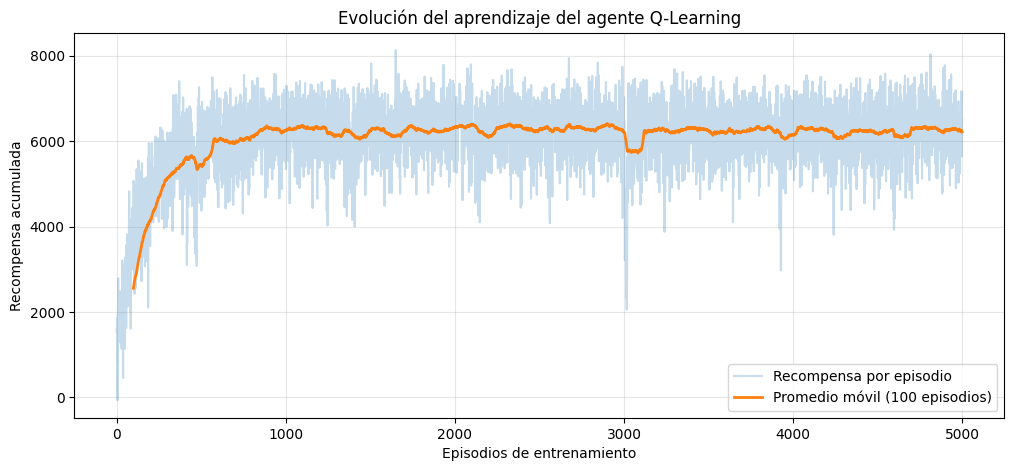

Recompensa promedio: 6058.82
Recompensa máxima: 8127
Recompensa mínima: -65


In [5]:

# Visualización de las recompensas del entrenamiento

plt.figure(figsize=(12, 5))

plt.plot(
    historial_recompensas,
    alpha=0.25,
    label="Recompensa por episodio"
)

# Calcular promedio móvil de 100 episodios
promedio_movil = pd.Series(
    historial_recompensas
).rolling(window=100).mean()

plt.plot(
    promedio_movil,
    linewidth=2,
    label="Promedio móvil (100 episodios)"
)

plt.title("Evolución del aprendizaje del agente Q-Learning")
plt.xlabel("Episodios de entrenamiento")
plt.ylabel("Recompensa acumulada")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

# Resultados generales
print("Recompensa promedio:",
      round(np.mean(historial_recompensas), 2))

print("Recompensa máxima:",
      round(np.max(historial_recompensas), 2))

print("Recompensa mínima:",
      round(np.min(historial_recompensas), 2))


In [6]:

# Evaluación del agente Q-Learning entrenado

episodios_prueba = 100
dias_prueba = 30

# Desactivar exploración durante la evaluación
epsilon_anterior = agente.epsilon
agente.epsilon = 0

resultados_evaluacion = []

for episodio in range(episodios_prueba):

    inventario = entorno.reiniciar()

    recompensa_total = 0
    ventas_totales = 0
    demanda_total = 0
    agotados_totales = 0
    almacenamiento_total = 0

    for dia in range(dias_prueba):

        estado = agente.obtener_estado(inventario)

        accion = agente.elegir_accion(estado)

        abastecimiento = (
            np.array(agente.acciones[accion]) * 2
        )

        inventario, recompensa, info = (
            entorno.ejecutar_dia(abastecimiento)
        )

        recompensa_total += recompensa
        ventas_totales += np.sum(info["ventas"])
        demanda_total += np.sum(info["demanda"])
        agotados_totales += np.sum(info["agotados"])
        almacenamiento_total += (
            info["costos_almacenamiento"]
        )

    resultados_evaluacion.append({
        "recompensa": recompensa_total,
        "ventas": ventas_totales,
        "demanda": demanda_total,
        "agotados": agotados_totales,
        "almacenamiento": almacenamiento_total
    })

# Restaurar el valor anterior de epsilon
agente.epsilon = epsilon_anterior

# Crear tabla de resultados
df_evaluacion = pd.DataFrame(resultados_evaluacion)

print("EVALUACIÓN DEL AGENTE Q-LEARNING")
print("--------------------------------")

print("Recompensa promedio:",
      round(df_evaluacion["recompensa"].mean(), 2))

print("Ventas promedio:",
      round(df_evaluacion["ventas"].mean(), 2))

print("Demanda promedio:",
      round(df_evaluacion["demanda"].mean(), 2))

print("Unidades agotadas promedio:",
      round(df_evaluacion["agotados"].mean(), 2))

print("Costo de almacenamiento promedio:",
      round(df_evaluacion["almacenamiento"].mean(), 2))


EVALUACIÓN DEL AGENTE Q-LEARNING
--------------------------------
Recompensa promedio: 6294.55
Ventas promedio: 332.37
Demanda promedio: 451.33
Unidades agotadas promedio: 118.96
Costo de almacenamiento promedio: 230.3


In [7]:

# Comparación entre Q-Learning y estrategia tradicional

def evaluar_metodo(tipo, episodios=100, dias=30):

    resultados = []

    for episodio in range(episodios):

        # Reiniciar la semilla para usar la misma demanda
        np.random.seed(1000 + episodio)

        entorno_prueba = TiendaCalzado()
        inventario = entorno_prueba.reiniciar()

        recompensa_total = 0
        ventas_total = 0
        demanda_total = 0
        agotados_total = 0
        almacenamiento_total = 0

        for dia in range(dias):

            if tipo == "Q-Learning":

                estado = agente.obtener_estado(inventario)
                accion = np.argmax(agente.Q[estado])

            else:

                # Política tradicional de abastecimiento
                acciones = []

                for unidades in inventario:

                    if unidades <= 4:
                        acciones.append(2)

                    elif unidades <= 9:
                        acciones.append(1)

                    else:
                        acciones.append(0)

                # Convertir las acciones en un índice
                accion = (
                    acciones[0] * 9 +
                    acciones[1] * 3 +
                    acciones[2]
                )

            abastecimiento = (
                np.array(agente.acciones[accion]) * 2
            )

            inventario, recompensa, info = (
                entorno_prueba.ejecutar_dia(abastecimiento)
            )

            recompensa_total += recompensa
            ventas_total += np.sum(info["ventas"])
            demanda_total += np.sum(info["demanda"])
            agotados_total += np.sum(info["agotados"])
            almacenamiento_total += (
                info["costos_almacenamiento"]
            )

        resultados.append({
            "Método": tipo,
            "Recompensa": recompensa_total,
            "Ventas": ventas_total,
            "Demanda": demanda_total,
            "Agotados": agotados_total,
            "Almacenamiento": almacenamiento_total
        })

    return pd.DataFrame(resultados)


# Evaluar ambos métodos
resultados_q = evaluar_metodo("Q-Learning")
resultados_tradicional = evaluar_metodo("Tradicional")

# Unir resultados
comparacion = pd.concat(
    [resultados_q, resultados_tradicional],
    ignore_index=True
)

# Calcular promedios
resumen = comparacion.groupby("Método").mean(numeric_only=True)

print("COMPARACIÓN DE RESULTADOS")
display(resumen.round(2))


COMPARACIÓN DE RESULTADOS


,Recompensa,Ventas,Demanda,Agotados,Almacenamiento
Método,,,,,
Q-Learning,6207.86,329.95,450.52,120.57,232.34
Tradicional,7223.60,356.19,450.52,94.33,266.20


In [8]:

# Mejora del algoritmo Q-Learning

# Actualización corregida de la tabla Q
def actualizar_mejorado(
    self,
    estado,
    accion,
    recompensa,
    nuevo_estado,
    terminado=False
):

    if terminado:
        mejor_valor_futuro = 0
    else:
        mejor_valor_futuro = np.max(
            self.Q[nuevo_estado]
        )

    valor_actual = self.Q[estado, accion]

    nuevo_valor = valor_actual + self.alpha * (
        recompensa +
        self.gamma * mejor_valor_futuro -
        valor_actual
    )

    self.Q[estado, accion] = nuevo_valor


AgenteQLearning.actualizar = actualizar_mejorado

# Crear un agente nuevo
agente_mejorado = AgenteQLearning()

# Ajustar parámetros
agente_mejorado.alpha = 0.1
agente_mejorado.gamma = 0.90
agente_mejorado.epsilon = 1.0
agente_mejorado.epsilon_min = 0.01
agente_mejorado.epsilon_decay = 0.999

# Entrenamiento ampliado
episodios_mejorados = 10000
dias_por_episodio = 30

historial_mejorado = []

entorno_mejorado = TiendaCalzado()

for episodio in range(episodios_mejorados):

    inventario = entorno_mejorado.reiniciar()
    recompensa_total = 0

    for dia in range(dias_por_episodio):

        estado = agente_mejorado.obtener_estado(inventario)

        accion = agente_mejorado.elegir_accion(estado)

        abastecimiento = (
            np.array(agente_mejorado.acciones[accion]) * 2
        )

        nuevo_inventario, recompensa, info = (
            entorno_mejorado.ejecutar_dia(abastecimiento)
        )

        nuevo_estado = agente_mejorado.obtener_estado(
            nuevo_inventario
        )

        terminado = (dia == dias_por_episodio - 1)

        agente_mejorado.actualizar(
            estado,
            accion,
            recompensa,
            nuevo_estado,
            terminado
        )

        inventario = nuevo_inventario
        recompensa_total += recompensa

    historial_mejorado.append(recompensa_total)

    agente_mejorado.reducir_exploracion()

print("Segundo entrenamiento finalizado.")
print("Episodios:", episodios_mejorados)
print("Días simulados:", episodios_mejorados * dias_por_episodio)
print("Epsilon final:", round(agente_mejorado.epsilon, 4))


Segundo entrenamiento finalizado.
Episodios: 10000
Días simulados: 300000
Epsilon final: 0.01


In [9]:

# Evaluación del agente Q-Learning mejorado

def evaluar_agente_mejorado(episodios=100, dias=30):

    resultados = []

    for episodio in range(episodios):

        np.random.seed(1000 + episodio)

        entorno_prueba = TiendaCalzado()
        inventario = entorno_prueba.reiniciar()

        recompensa_total = 0
        ventas_total = 0
        demanda_total = 0
        agotados_total = 0
        almacenamiento_total = 0

        for dia in range(dias):

            estado = agente_mejorado.obtener_estado(
                inventario
            )

            accion = np.argmax(
                agente_mejorado.Q[estado]
            )

            abastecimiento = (
                np.array(agente_mejorado.acciones[accion]) * 2
            )

            inventario, recompensa, info = (
                entorno_prueba.ejecutar_dia(abastecimiento)
            )

            recompensa_total += recompensa
            ventas_total += np.sum(info["ventas"])
            demanda_total += np.sum(info["demanda"])
            agotados_total += np.sum(info["agotados"])
            almacenamiento_total += (
                info["costos_almacenamiento"]
            )

        resultados.append({
            "Recompensa": recompensa_total,
            "Ventas": ventas_total,
            "Demanda": demanda_total,
            "Agotados": agotados_total,
            "Almacenamiento": almacenamiento_total
        })

    return pd.DataFrame(resultados)


# Ejecutar evaluación
df_mejorado = evaluar_agente_mejorado()

# Mostrar indicadores
print("EVALUACIÓN DEL AGENTE MEJORADO")
print("--------------------------------")

print("Recompensa promedio:",
      round(df_mejorado["Recompensa"].mean(), 2))

print("Ventas promedio:",
      round(df_mejorado["Ventas"].mean(), 2))

print("Demanda promedio:",
      round(df_mejorado["Demanda"].mean(), 2))

print("Agotados promedio:",
      round(df_mejorado["Agotados"].mean(), 2))

print("Almacenamiento promedio:",
      round(df_mejorado["Almacenamiento"].mean(), 2))


EVALUACIÓN DEL AGENTE MEJORADO
--------------------------------
Recompensa promedio: 7043.92
Ventas promedio: 350.78
Demanda promedio: 450.52
Agotados promedio: 99.74
Almacenamiento promedio: 229.48


TABLA COMPARATIVA FINAL


,Q-Learning inicial,Q-Learning mejorado,Tradicional
Recompensa,6207.86,7043.92,7223.60
Ventas,329.95,350.78,356.19
Demanda,450.52,450.52,450.52
Agotados,120.57,99.74,94.33
Almacenamiento,232.34,229.48,266.20


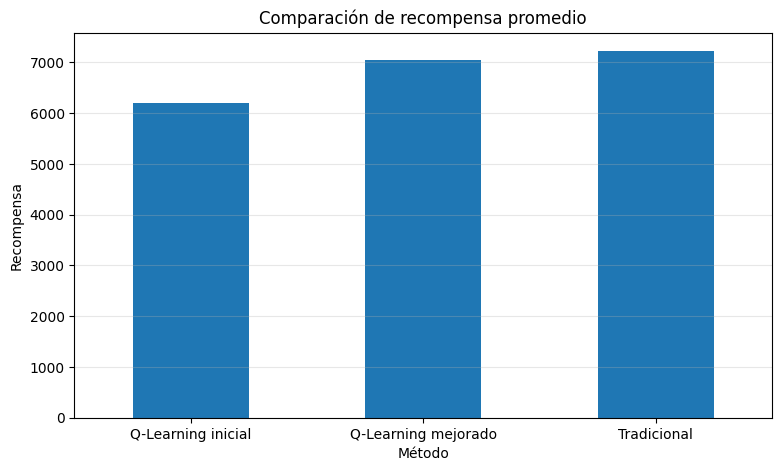

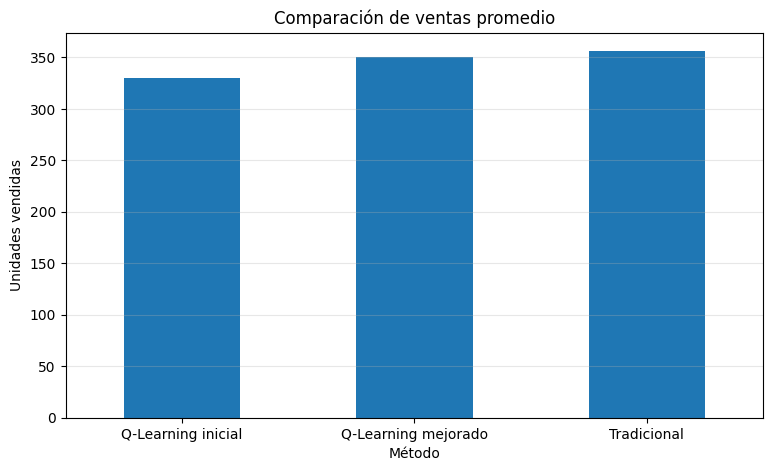

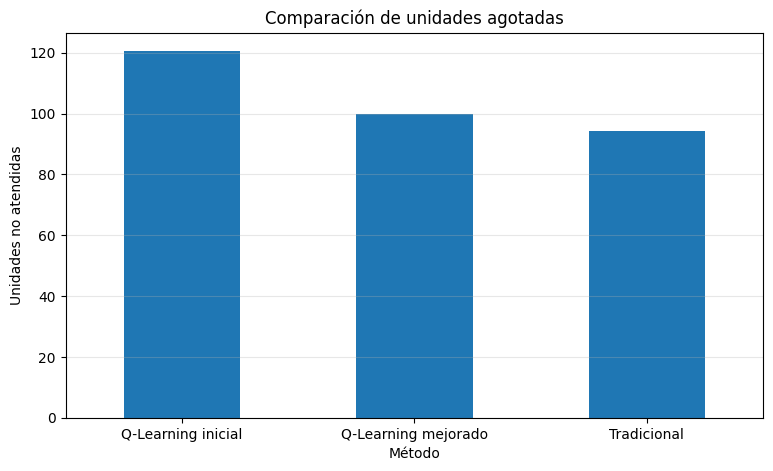

In [10]:

# Construcción de la tabla comparativa final

resumen_final = pd.DataFrame({
    "Q-Learning inicial": comparacion[
        comparacion["Método"] == "Q-Learning"
    ].drop(columns="Método").mean(),

    "Q-Learning mejorado": df_mejorado.mean(),

    "Tradicional": resultados_tradicional.drop(
        columns="Método"
    ).mean()
})

print("TABLA COMPARATIVA FINAL")
display(resumen_final.round(2))


# Gráfica 1: Recompensa promedio
plt.figure(figsize=(9, 5))

resumen_final.loc["Recompensa"].plot(
    kind="bar",
    rot=0
)

plt.title("Comparación de recompensa promedio")
plt.ylabel("Recompensa")
plt.xlabel("Método")
plt.grid(axis="y", alpha=0.3)
plt.show()


# Gráfica 2: Ventas promedio
plt.figure(figsize=(9, 5))

resumen_final.loc["Ventas"].plot(
    kind="bar",
    rot=0
)

plt.title("Comparación de ventas promedio")
plt.ylabel("Unidades vendidas")
plt.xlabel("Método")
plt.grid(axis="y", alpha=0.3)
plt.show()


# Gráfica 3: Unidades agotadas
plt.figure(figsize=(9, 5))

resumen_final.loc["Agotados"].plot(
    kind="bar",
    rot=0
)

plt.title("Comparación de unidades agotadas")
plt.ylabel("Unidades no atendidas")
plt.xlabel("Método")
plt.grid(axis="y", alpha=0.3)
plt.show()


In [11]:

# Análisis de las decisiones aprendidas por Q-Learning

niveles_inventario = [0, 5, 10]

resultados_politica = []

for deportivo in niveles_inventario:
    for formal in niveles_inventario:
        for sandalias in niveles_inventario:

            inventario = np.array([
                deportivo,
                formal,
                sandalias
            ])

            estado = agente_mejorado.obtener_estado(
                inventario
            )

            accion = np.argmax(
                agente_mejorado.Q[estado]
            )

            abastecimiento = (
                np.array(agente_mejorado.acciones[accion]) * 2
            )

            resultados_politica.append({
                "Deportivo": deportivo,
                "Formal": formal,
                "Sandalias": sandalias,
                "Solicitar deportivo": abastecimiento[0],
                "Solicitar formal": abastecimiento[1],
                "Solicitar sandalias": abastecimiento[2]
            })

df_politica = pd.DataFrame(resultados_politica)

print("POLÍTICA DE ABASTECIMIENTO APRENDIDA")
display(df_politica)


POLÍTICA DE ABASTECIMIENTO APRENDIDA


,Deportivo,Formal,Sandalias,Solicitar deportivo,Solicitar formal,Solicitar sandalias
0,0,0,0,4,4,4
1,0,0,5,4,4,0
2,0,0,10,2,4,2
3,0,5,0,4,0,4
4,0,5,5,4,0,2
5,0,5,10,0,0,0
6,0,10,0,2,0,4
7,0,10,5,4,0,4
8,0,10,10,0,0,0
9,5,0,0,0,4,4


In [14]:
# Evaluación de la recompensa del agente mejorado

promedio_recompensa_mejorado = np.mean(
    historial_mejorado[-1000:]
)

print(
    "Recompensa promedio de los últimos 1000 episodios:",
    round(promedio_recompensa_mejorado, 2)
)

Recompensa promedio de los últimos 1000 episodios: 6963.47


In [15]:
# Política de abastecimiento del agente mejorado actualizado

niveles_inventario = [0, 5, 10]

resultados_politica_actualizada = []

for deportivo in niveles_inventario:
    for formal in niveles_inventario:
        for sandalias in niveles_inventario:

            inventario = np.array([
                deportivo,
                formal,
                sandalias
            ])

            estado = agente_mejorado.obtener_estado(
                inventario
            )

            accion = np.argmax(
                agente_mejorado.Q[estado]
            )

            abastecimiento = (
                np.array(agente_mejorado.acciones[accion]) * 2
            )

            resultados_politica_actualizada.append({
                "Deportivo": deportivo,
                "Formal": formal,
                "Sandalias": sandalias,
                "Solicitar deportivo": abastecimiento[0],
                "Solicitar formal": abastecimiento[1],
                "Solicitar sandalias": abastecimiento[2]
            })

df_politica_actualizada = pd.DataFrame(
    resultados_politica_actualizada
)

print("POLÍTICA DE ABASTECIMIENTO ACTUALIZADA")
display(df_politica_actualizada)

POLÍTICA DE ABASTECIMIENTO ACTUALIZADA


,Deportivo,Formal,Sandalias,Solicitar deportivo,Solicitar formal,Solicitar sandalias
0,0,0,0,4,4,4
1,0,0,5,4,4,0
2,0,0,10,2,4,2
3,0,5,0,4,0,4
4,0,5,5,4,0,2
5,0,5,10,0,0,0
6,0,10,0,2,0,4
7,0,10,5,4,0,4
8,0,10,10,0,0,0
9,5,0,0,0,4,4


In [17]:
# Comparación de políticas de abastecimiento

politica_anterior = [
    [4,4,4], [4,4,0], [2,4,2],
    [4,0,4], [4,0,2], [0,0,0],
    [2,0,4], [4,0,4], [0,0,0],
    [0,4,4], [2,2,0], [0,2,0],
    [0,0,0], [0,0,4], [0,2,2],
    [0,0,4], [2,0,4], [2,0,4],
    [0,2,0], [0,4,2], [2,2,2],
    [2,4,0], [2,2,0], [2,4,2],
    [0,0,0], [0,0,2], [0,0,2]
]

politica_nueva = df_politica_actualizada[
    [
        "Solicitar deportivo",
        "Solicitar formal",
        "Solicitar sandalias"
    ]
].values.tolist()

comparacion = []

for i in range(27):

    comparacion.append({
        "Estado": i,
        "Política anterior": politica_anterior[i],
        "Política actualizada": politica_nueva[i],
        "¿Cambió la decisión?": (
            politica_anterior[i] != politica_nueva[i]
        )
    })

df_comparacion = pd.DataFrame(comparacion)

display(df_comparacion)

print(
    "Estados con cambios:",
    df_comparacion["¿Cambió la decisión?"].sum()
)

,Estado,Política anterior,Política actualizada,¿Cambió la decisión?
0,0,"[4, 4, 4]","[4, 4, 4]",False
1,1,"[4, 4, 0]","[4, 4, 0]",False
2,2,"[2, 4, 2]","[2, 4, 2]",False
3,3,"[4, 0, 4]","[4, 0, 4]",False
4,4,"[4, 0, 2]","[4, 0, 2]",False
5,5,"[0, 0, 0]","[0, 0, 0]",False
6,6,"[2, 0, 4]","[2, 0, 4]",False
7,7,"[4, 0, 4]","[4, 0, 4]",False
8,8,"[0, 0, 0]","[0, 0, 0]",False
9,9,"[0, 4, 4]","[0, 4, 4]",False


Estados con cambios: 1


In [18]:

# Evaluación independiente del agente mejorado

entorno_evaluacion = TiendaCalzado()

inventario = entorno_evaluacion.reiniciar()

recompensas_evaluacion = []
costos_abastecimiento_evaluacion = []
ventas_evaluacion = []
agotados_evaluacion = []

for dia in range(1000):

    estado = agente_mejorado.obtener_estado(inventario)

    accion = np.argmax(agente_mejorado.Q[estado])

    abastecimiento = (
        np.array(agente_mejorado.acciones[accion]) * 2
    )

    nuevo_inventario, recompensa, info = (
        entorno_evaluacion.ejecutar_dia(abastecimiento)
    )

    recompensas_evaluacion.append(recompensa)

    costos_abastecimiento_evaluacion.append(
        info["costos_abastecimiento"]
    )

    ventas_evaluacion.append(np.sum(info["ventas"]))

    agotados_evaluacion.append(np.sum(info["agotados"]))

    inventario = nuevo_inventario

print("RESULTADOS DE EVALUACIÓN")
print("Días evaluados:", 1000)
print("Recompensa promedio diaria:",
      round(np.mean(recompensas_evaluacion), 2))
print("Recompensa total:",
      round(np.sum(recompensas_evaluacion), 2))
print("Costo total de abastecimiento:",
      round(np.sum(costos_abastecimiento_evaluacion), 2))
print("Unidades vendidas:",
      np.sum(ventas_evaluacion))
print("Unidades agotadas:",
      np.sum(agotados_evaluacion))


RESULTADOS DE EVALUACIÓN
Días evaluados: 1000
Recompensa promedio diaria: 170.39
Recompensa total: 170386
Costo total de abastecimiento: 57590
Unidades vendidas: 11545
Unidades agotadas: 3647


### Interpretación de los resultados de la evaluación

La evaluación independiente del agente mejorado se realizó durante 1.000 días de simulación, utilizando una política de abastecimiento basada en la tabla Q aprendida. Se obtuvo una recompensa económica total de 170.386 y un promedio diario de 170,39. Durante este periodo se registraron 11.545 unidades vendidas y 3.647 unidades de demanda no atendida. El costo acumulado de abastecimiento fue de 57.590.

Estos resultados muestran que el agente mantiene una recompensa positiva bajo la nueva estructura de costos, aunque todavía presenta oportunidades de mejora en la disponibilidad de productos.

In [19]:

# Evaluación de una estrategia tradicional de abastecimiento

entorno_tradicional = TiendaCalzado()

inventario = entorno_tradicional.reiniciar()

recompensas_tradicional = []
ventas_tradicional = []
agotados_tradicional = []
costos_abastecimiento_tradicional = []

for dia in range(1000):

    abastecimiento = np.array([2, 2, 2])

    nuevo_inventario, recompensa, info = (
        entorno_tradicional.ejecutar_dia(abastecimiento)
    )

    recompensas_tradicional.append(recompensa)
    ventas_tradicional.append(np.sum(info["ventas"]))
    agotados_tradicional.append(np.sum(info["agotados"]))

    costos_abastecimiento_tradicional.append(
        info["costos_abastecimiento"]
    )

    inventario = nuevo_inventario

print("RESULTADOS DE LA ESTRATEGIA TRADICIONAL")
print("Días evaluados:", 1000)

print("Recompensa promedio diaria:",
      round(np.mean(recompensas_tradicional), 2))

print("Recompensa total:",
      round(np.sum(recompensas_tradicional), 2))

print("Unidades vendidas:",
      np.sum(ventas_tradicional))

print("Unidades agotadas:",
      np.sum(agotados_tradicional))

print("Costo total de abastecimiento:",
      np.sum(costos_abastecimiento_tradicional))


RESULTADOS DE LA ESTRATEGIA TRADICIONAL
Días evaluados: 1000
Recompensa promedio diaria: -16.45
Recompensa total: -16447
Unidades vendidas: 6030
Unidades agotadas: 9111
Costo total de abastecimiento: 30000


### Comparación entre el agente Q-Learning y la estrategia tradicional

La evaluación comparativa se realizó durante 1.000 días de simulación para cada estrategia, utilizando los mismos parámetros económicos y condiciones del entorno. El agente Q-Learning obtuvo una recompensa total de 170.386, mientras que la estrategia tradicional presentó una recompensa de -16.447.

En términos de ventas, el agente inteligente alcanzó 11.545 unidades, frente a 6.030 de la estrategia tradicional. Asimismo, registró 3.647 unidades de demanda no atendida, mientras que la estrategia tradicional presentó 9.111.

Estos resultados evidencian un mejor desempeño del agente Q-Learning en las simulaciones realizadas. Aunque su costo de abastecimiento fue superior, logró mayores ventas, redujo los agotados y obtuvo una recompensa económica positiva. Por tanto, el aprendizaje por refuerzo representa una alternativa prometedora para apoyar las decisiones de abastecimiento de la tienda de calzado.

In [20]:

# Comparación con las mismas semillas de demanda

resultados_comparacion = []

for semilla in range(100):

    # Evaluar Q-Learning
    np.random.seed(semilla)

    entorno_q = TiendaCalzado()
    inventario_q = entorno_q.reiniciar()
    recompensa_q = 0

    for dia in range(1000):

        estado = agente_mejorado.obtener_estado(inventario_q)
        accion = np.argmax(agente_mejorado.Q[estado])

        abastecimiento = (
            np.array(agente_mejorado.acciones[accion]) * 2
        )

        inventario_q, recompensa, info = (
            entorno_q.ejecutar_dia(abastecimiento)
        )

        recompensa_q += recompensa

    # Evaluar estrategia tradicional con la misma demanda
    np.random.seed(semilla)

    entorno_t = TiendaCalzado()
    inventario_t = entorno_t.reiniciar()
    recompensa_t = 0

    for dia in range(1000):

        abastecimiento = np.array([2, 2, 2])

        inventario_t, recompensa, info = (
            entorno_t.ejecutar_dia(abastecimiento)
        )

        recompensa_t += recompensa

    resultados_comparacion.append({
        "Semilla": semilla,
        "Q-Learning": recompensa_q,
        "Tradicional": recompensa_t
    })

df_comparacion_final = pd.DataFrame(resultados_comparacion)

print("PROMEDIO DE RECOMPENSA EN 100 EVALUACIONES")
print("Q-Learning:",
      round(df_comparacion_final["Q-Learning"].mean(), 2))

print("Tradicional:",
      round(df_comparacion_final["Tradicional"].mean(), 2))

print("Diferencia:",
      round(
          (df_comparacion_final["Q-Learning"] -
           df_comparacion_final["Tradicional"]).mean(), 2
      ))


PROMEDIO DE RECOMPENSA EN 100 EVALUACIONES
Q-Learning: 170772.76
Tradicional: -14342.3
Diferencia: 185115.06


### Comparación controlada de las estrategias de abastecimiento

Para comprobar el desempeño de las estrategias bajo condiciones comparables, se realizaron 100 evaluaciones de 1.000 días cada una, utilizando las mismas semillas de generación de demanda para el agente Q-Learning y la estrategia tradicional.

Los resultados muestran que el agente Q-Learning obtuvo una recompensa promedio de **170.772,76**, mientras que la estrategia tradicional registró una recompensa promedio de **-14.342,30**. La diferencia promedio entre ambas estrategias fue de **185.115,06** a favor del agente inteligente.

Estos resultados indican que Q-Learning logró un mejor desempeño económico en las simulaciones realizadas. Al enfrentar ambas estrategias a las mismas secuencias de demanda, la comparación reduce el efecto de la variabilidad aleatoria y permite atribuir con mayor confianza la diferencia observada a las decisiones de abastecimiento.

Por tanto, los resultados respaldan el uso del aprendizaje por refuerzo como una alternativa para mejorar las decisiones de inventario en la tienda de calzado.

In [21]:

from scipy import stats
import numpy as np

# Estadísticas descriptivas
media_q = df_comparacion_final["Q-Learning"].mean()
desviacion_q = df_comparacion_final["Q-Learning"].std()

media_t = df_comparacion_final["Tradicional"].mean()
desviacion_t = df_comparacion_final["Tradicional"].std()

print("ESTADÍSTICAS DESCRIPTIVAS")
print("--------------------------------")
print(f"Q-Learning - Promedio: {media_q:.2f}")
print(f"Q-Learning - Desviación estándar: {desviacion_q:.2f}")

print()

print(f"Tradicional - Promedio: {media_t:.2f}")
print(f"Tradicional - Desviación estándar: {desviacion_t:.2f}")

# Diferencias entre evaluaciones emparejadas
diferencias = (
    df_comparacion_final["Q-Learning"] -
    df_comparacion_final["Tradicional"]
)

print()
print("DIFERENCIA ENTRE ESTRATEGIAS")
print("--------------------------------")
print(f"Diferencia promedio: {diferencias.mean():.2f}")
print(f"Desviación estándar: {diferencias.std():.2f}")

# Prueba t de Student para muestras relacionadas
estadistico_t, valor_p = stats.ttest_rel(
    df_comparacion_final["Q-Learning"],
    df_comparacion_final["Tradicional"]
)

print()
print("PRUEBA T DE STUDENT PARA MUESTRAS RELACIONADAS")
print("--------------------------------")
print(f"Estadístico t: {estadistico_t:.4f}")
print(f"Valor p: {valor_p:.10f}")

# Intervalo de confianza del 95 % para la diferencia promedio
n = len(diferencias)
error_estandar = stats.sem(diferencias)
valor_critico = stats.t.ppf(0.975, df=n - 1)

limite_inferior = diferencias.mean() - valor_critico * error_estandar
limite_superior = diferencias.mean() + valor_critico * error_estandar

print()
print("INTERVALO DE CONFIANZA DEL 95 %")
print("--------------------------------")
print(f"Límite inferior: {limite_inferior:.2f}")
print(f"Límite superior: {limite_superior:.2f}")

if valor_p < 0.05:
    print("\nResultado: La diferencia es estadísticamente significativa.")
else:
    print("\nResultado: No se encontró una diferencia estadísticamente significativa.")


ESTADÍSTICAS DESCRIPTIVAS
--------------------------------
Q-Learning - Promedio: 170772.76
Q-Learning - Desviación estándar: 1593.87

Tradicional - Promedio: -14342.30
Tradicional - Desviación estándar: 2064.39

DIFERENCIA ENTRE ESTRATEGIAS
--------------------------------
Diferencia promedio: 185115.06
Desviación estándar: 1651.17

PRUEBA T DE STUDENT PARA MUESTRAS RELACIONADAS
--------------------------------
Estadístico t: 1121.1138
Valor p: 0.0000000000

INTERVALO DE CONFIANZA DEL 95 %
--------------------------------
Límite inferior: 184787.43
Límite superior: 185442.69

Resultado: La diferencia es estadísticamente significativa.


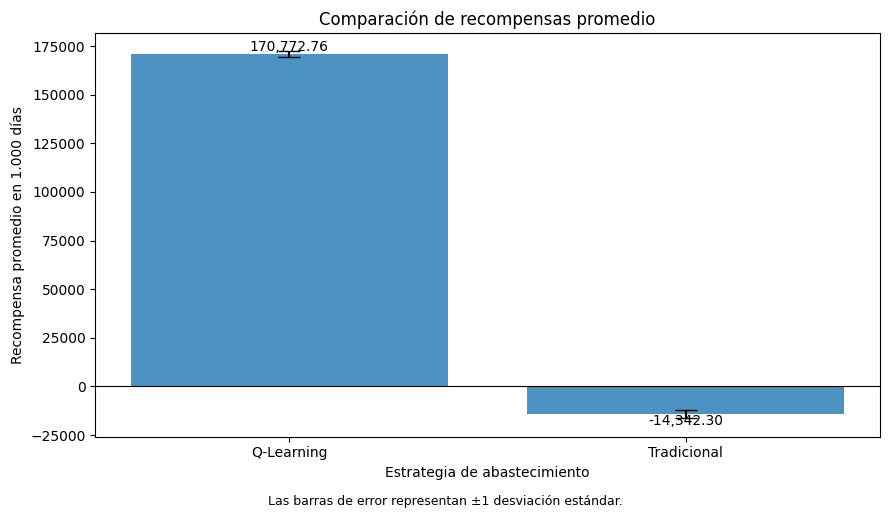

In [22]:

import matplotlib.pyplot as plt
import numpy as np

# Promedios y desviaciones estándar
promedios = [
    df_comparacion_final["Q-Learning"].mean(),
    df_comparacion_final["Tradicional"].mean()
]

desviaciones = [
    df_comparacion_final["Q-Learning"].std(),
    df_comparacion_final["Tradicional"].std()
]

estrategias = ["Q-Learning", "Tradicional"]

# Crear gráfica
plt.figure(figsize=(9, 5))

barras = plt.bar(
    estrategias,
    promedios,
    yerr=desviaciones,
    capsize=8,
    alpha=0.8
)

plt.axhline(0, color="black", linewidth=0.8)

plt.title("Comparación de recompensas promedio")
plt.ylabel("Recompensa promedio en 1.000 días")
plt.xlabel("Estrategia de abastecimiento")

# Mostrar valores sobre las barras
for barra, valor in zip(barras, promedios):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        valor,
        f"{valor:,.2f}",
        ha="center",
        va="bottom" if valor >= 0 else "top"
    )

plt.figtext(
    0.5, -0.02,
    "Las barras de error representan ±1 desviación estándar.",
    ha="center",
    fontsize=9
)

plt.tight_layout()
plt.show()


# Análisis de significancia estadística

Se realizó una prueba t de Student para muestras relacionadas, utilizando los resultados de 100 evaluaciones de ambas estrategias bajo las mismas secuencias de demanda.

El agente Q-Learning obtuvo una recompensa promedio de 170.772,76, con una desviación estándar de 1.593,87. Por su parte, la estrategia tradicional registró una recompensa promedio de -14.342,30 y una desviación estándar de 2.064,39.

La diferencia promedio entre las estrategias fue de 185.115,06. La prueba estadística arrojó un valor t de 1121,1138 y un valor p inferior a 0,001. Además, el intervalo de confianza del 95 % para la diferencia se ubicó entre 184.787,43 y 185.442,69.

Debido a que el valor p es inferior al nivel de significancia de 0,05 y el intervalo de confianza no contiene el cero, se rechaza la hipótesis nula. Esto indica que existe una diferencia estadísticamente significativa entre las recompensas promedio de las dos estrategias.

Los resultados respaldan el mejor desempeño económico del agente Q-Learning frente a la estrategia tradicional en las condiciones evaluadas.

## Conclusiones generales

El desarrollo de este proyecto permitió implementar un modelo de aprendizaje por refuerzo basado en Q-Learning para apoyar las decisiones de abastecimiento en una tienda de calzado, considerando tres categorías de productos: deportivo, formal y sandalias.

Mediante la simulación de diferentes escenarios de inventario y demanda, el agente aprendió a seleccionar cantidades de abastecimiento de acuerdo con los niveles de existencias y las recompensas obtenidas. De esta manera, se construyó una política de decisión orientada a mejorar el rendimiento económico de la tienda.

Los resultados de las evaluaciones comparativas mostraron un mejor desempeño del agente Q-Learning frente a la estrategia tradicional de abastecimiento fijo. En las 100 evaluaciones realizadas, el agente obtuvo una recompensa promedio de 170.772,76, mientras que la estrategia tradicional registró -14.342,30. La diferencia promedio fue de 185.115,06 a favor del modelo de aprendizaje por refuerzo.

La prueba t de Student para muestras relacionadas confirmó que esta diferencia es estadísticamente significativa, con un valor p inferior a 0,001. Esto respalda los resultados obtenidos bajo las condiciones de simulación establecidas.

Finalmente, se concluye que el aprendizaje por refuerzo representa una alternativa útil para apoyar la gestión de inventarios y las decisiones de abastecimiento. Sin embargo, el modelo puede mejorarse mediante la incorporación de datos históricos reales de ventas, variaciones de demanda, tiempos de entrega de proveedores y costos específicos de cada categoría, con el propósito de acercar la simulación a las condiciones reales de operación de la tienda.

## Limitaciones del modelo

Aunque los resultados obtenidos fueron favorables para el agente Q-Learning, el proyecto presenta algunas limitaciones:

- **Demanda simulada:** se utilizó una distribución de Poisson para generar la demanda diaria, por lo que los datos no corresponden a registros históricos reales de ventas.
- **Categorías de productos:** el modelo contempla únicamente tres categorías: deportivo, formal y sandalias. No considera referencias, tallas, colores ni características individuales de cada producto.
- **Costos estimados:** los costos de almacenamiento, abastecimiento y agotamiento se definieron mediante valores simulados, por lo que pueden diferir de los costos reales de la tienda.
- **Condiciones de abastecimiento:** el modelo no contempla tiempos de entrega, retrasos de proveedores ni restricciones presupuestales.
- **Entorno controlado:** los resultados corresponden a simulaciones y no garantizan el mismo rendimiento en una operación comercial real.

## Recomendaciones para futuras mejoras

Para fortalecer el modelo y acercarlo a las condiciones reales de una tienda de calzado, se proponen las siguientes mejoras:

1. Incorporar registros históricos de ventas e inventarios para estimar la demanda con información real.
2. Ampliar el modelo para incluir referencias, tallas, colores y temporadas comerciales.
3. Ajustar los costos de almacenamiento, abastecimiento y agotamiento con datos financieros reales.
4. Incluir tiempos de entrega y restricciones presupuestales en las decisiones de abastecimiento.
5. Comparar diferentes algoritmos de aprendizaje por refuerzo para identificar cuál ofrece mejores resultados.
6. Realizar pruebas piloto con datos reales antes de implementar el modelo en la operación de una tienda.

Estas mejoras permitirían desarrollar una herramienta de apoyo para la toma de decisiones, con mayor precisión y adaptación a las necesidades comerciales del negocio.